In [6]:
# setting logging to print only error messages from Sklearnex
import logging
logging.basicConfig()
logging.getLogger("SKLEARNEX").setLevel(logging.ERROR)

import pandas as pd
import numpy as np
import seaborn as sns

import matplotlib.pyplot as plt

sns.set_theme(palette="Set2")

# Data loading

In [7]:
bank_data= pd.read_csv("Bank Customer Churn Prediction.csv")
bank_data.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [8]:
bank_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  object 
 3   gender            10000 non-null  object 
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), object(2)
memory usage: 937.6+ KB


**Notice**: No missing value

In [9]:
bank_data.shape

(10000, 12)

In [10]:
bank_data.duplicated().sum()

np.int64(0)

* Split the data

In [11]:
from sklearn.model_selection import train_test_split

# Split the dataset randomly into train (80%) and test (20%) sets
train_data, test_data = train_test_split(bank_data, test_size=0.2, random_state=42)

# Display dataset shapes
print(f"Train dataset shape: {train_data.shape}")
print(f"Test dataset shape: {test_data.shape}")

# Preview the training data
train_data.head()

Train dataset shape: (8000, 12)
Test dataset shape: (2000, 12)


,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
9254,15601116,686,France,Male,32,6,0.00,2,1,1,179093.26,0
1561,15766374,632,Germany,Male,42,4,119624.60,2,1,1,195978.86,0
1670,15716994,559,Spain,Male,24,3,114739.92,1,1,0,85891.02,1
6087,15730759,561,France,Female,27,9,135637.00,1,1,0,153080.40,1
6669,15797900,517,France,Male,56,9,142147.32,1,0,0,39488.04,1


# EDA

*Univariate dataset*

In [12]:
train_data.describe().round(2)

,customer_id,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
count,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00
mean,15690665.10,651.65,38.90,5.00,76102.14,1.53,0.70,0.51,100431.29,0.21
std,71847.43,96.37,10.52,2.88,62461.01,0.58,0.46,0.50,57518.92,0.40
min,15565701.00,350.00,18.00,0.00,0.00,1.00,0.00,0.00,90.07,0.00
25%,15628215.50,585.00,32.00,3.00,0.00,1.00,0.00,0.00,51364.12,0.00
50%,15690738.00,653.00,37.00,5.00,96447.52,1.00,1.00,1.00,100487.72,0.00
75%,15753164.25,719.00,44.00,7.00,127611.33,2.00,1.00,1.00,149595.84,0.00
max,15815660.00,850.00,92.00,10.00,250898.09,4.00,1.00,1.00,199970.74,1.00


In [13]:
# Identify object columns
object_cols = list(train_data.select_dtypes(include=['object']).columns)

# Identify binary columns (numerical columns containing only 0 and 1)
binary_cols = [col for col in train_data.select_dtypes(include=['number']).columns
               if set(train_data[col].unique()).issubset({0, 1})]




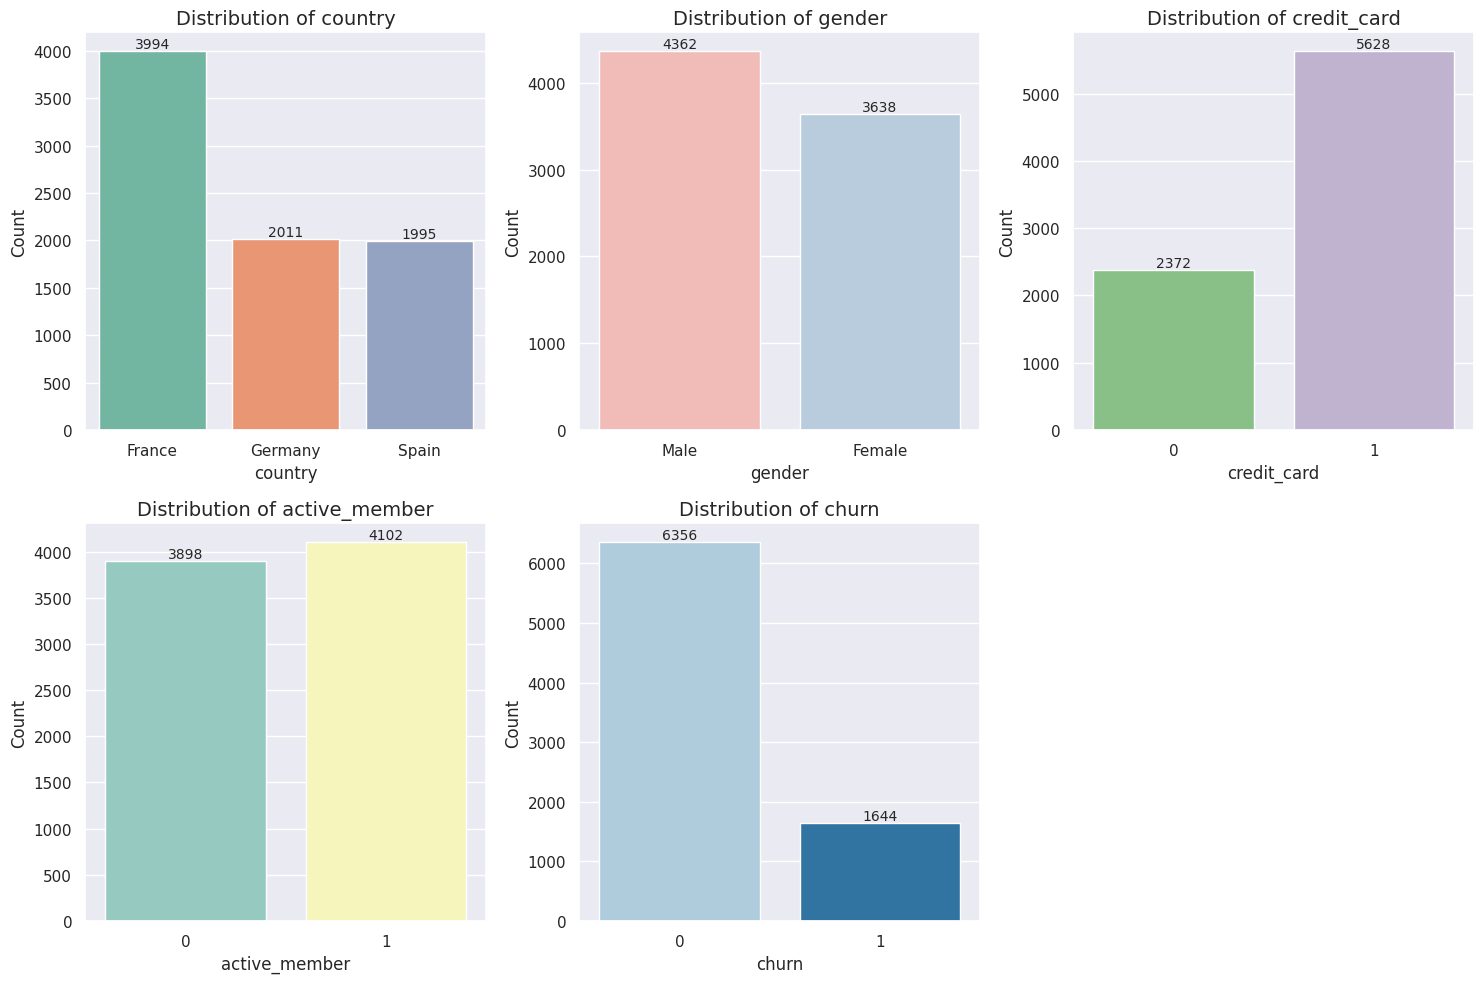

In [14]:
# Plot individual distribution charts for categorical and binary variables in 2 rows with distinct colors
import math

# Combine object and binary columns
object_cols_and_binary_cols = object_cols + binary_cols

cols_per_row = 3
num_cols = len(object_cols_and_binary_cols)
num_rows = math.ceil(num_cols / cols_per_row)

fig, axes = plt.subplots(nrows=num_rows, ncols=cols_per_row, figsize=(15, 5 * num_rows))
axes = axes.flatten()  # Flatten the 2D grid of axes for easy indexing

# Define a list of different palettes to use for each subplot
palettes = ['Set2', 'Pastel1', 'Accent', 'Set3', 'Paired']

for i, col in enumerate(object_cols_and_binary_cols):
    # Apply a unique palette for each chart, cycling through the list if necessary
    current_palette = palettes[i % len(palettes)]

    sns.countplot(data=train_data, x=col, ax=axes[i], palette=current_palette, hue=col, legend=False)
    axes[i].set_title(f"Distribution of {col}", fontsize=14)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel("Count", fontsize=12)

    # Add value labels on top of each bar
    for container in axes[i].containers:
        axes[i].bar_label(container, fontsize=10)

# Hide any unused subplots in the grid
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Country: France has the largest customer base (3,994), making it the bank’s most important market.



Gender: Male customers (4,362) slightly outnumber females (3,638), showing a relatively balanced customer base.



Credit Card: Most customers own credit cards (5,628), while non-cardholders offer opportunities for cross-selling.



Active Member: Active members (4,102) slightly exceed inactive members (3,898), suggesting room to improve customer engagement.



Churn: Around 20.6% of customers have left the bank, highlighting the need to strengthen customer retention.

In [15]:
train_data["churn"].value_counts(normalize=True) * 100

,proportion
churn,
0,79.45
1,20.55


There is some imbalance in the distribution of "credit_card", "active_member", and "churn".

About 80% of customers will not churn, which is much higher than the minority class. This class imbalance requires applying data balancing techniques to ensure the model achieves good accuracy and generalizes well.

In [16]:
train_data.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
9254,15601116,686,France,Male,32,6,0.00,2,1,1,179093.26,0
1561,15766374,632,Germany,Male,42,4,119624.60,2,1,1,195978.86,0
1670,15716994,559,Spain,Male,24,3,114739.92,1,1,0,85891.02,1
6087,15730759,561,France,Female,27,9,135637.00,1,1,0,153080.40,1
6669,15797900,517,France,Male,56,9,142147.32,1,0,0,39488.04,1


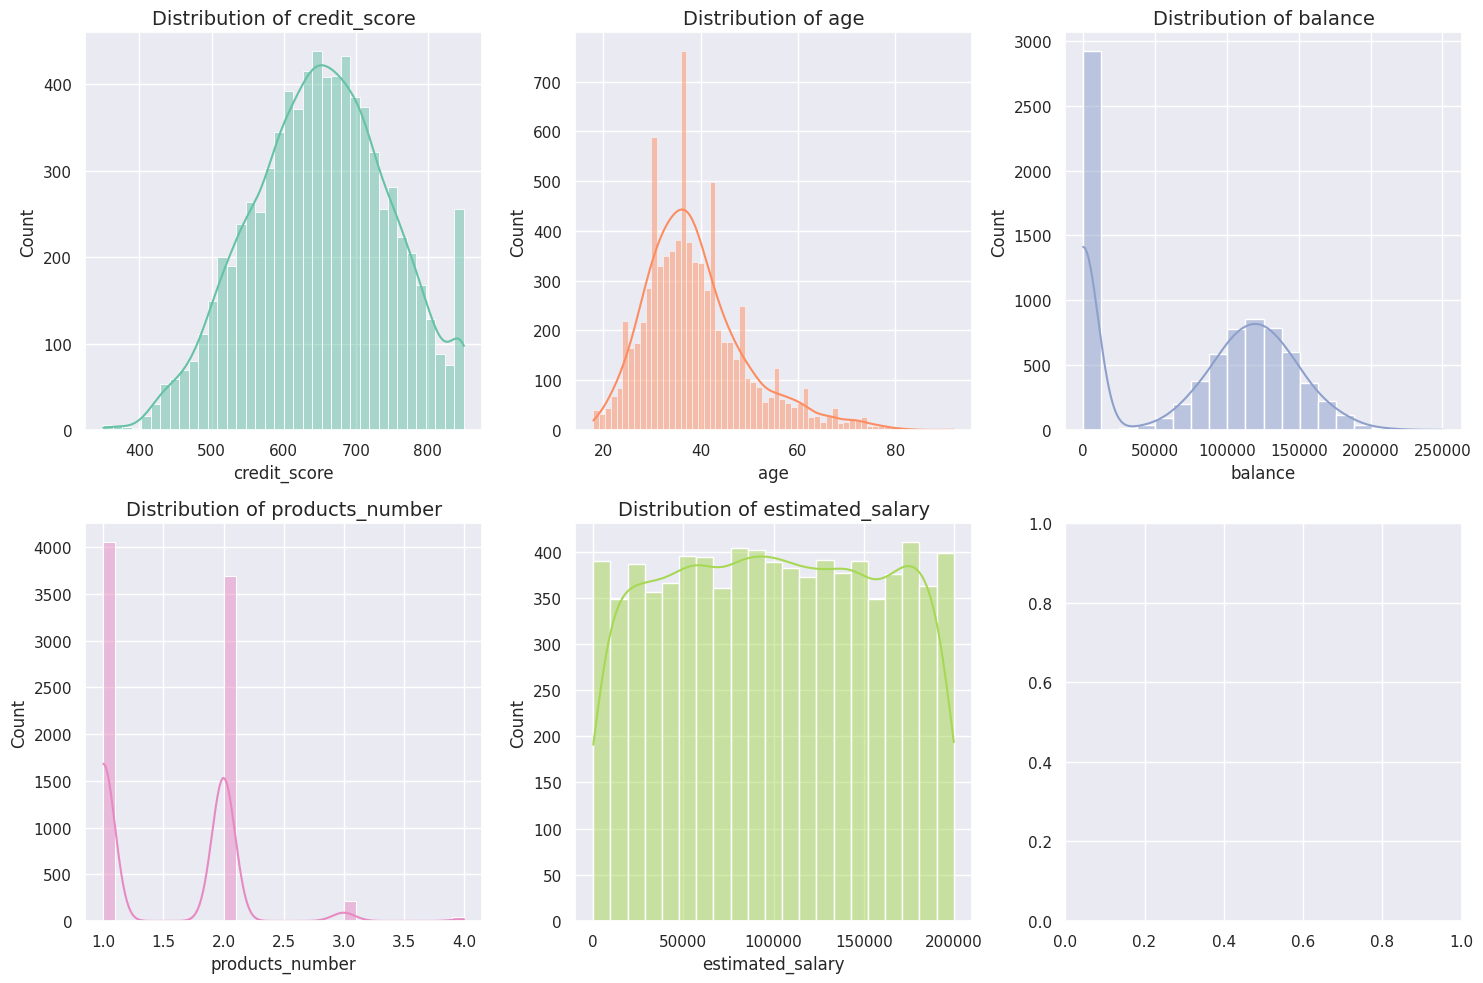

In [17]:
# Columns to plot
number_cols = ['credit_score', 'age', 'balance', 'products_number', 'estimated_salary']

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))
axes = axes.flatten()

# Get a list of individual colors from the 'Set2' palette
palette_colors = sns.color_palette("Set2", len(number_cols))

for i, col in enumerate(number_cols):
    # Use a unique single color from the palette for each histogram
    sns.histplot(data=train_data, x=col, ax=axes[i], kde=True, color=palette_colors[i])
    axes[i].set_title(f"Distribution of {col}", fontsize=14)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel("Count", fontsize=12) # Fixed y-label size so it is readable
    axes[i].tick_params(axis='x')

plt.tight_layout()
plt.show()

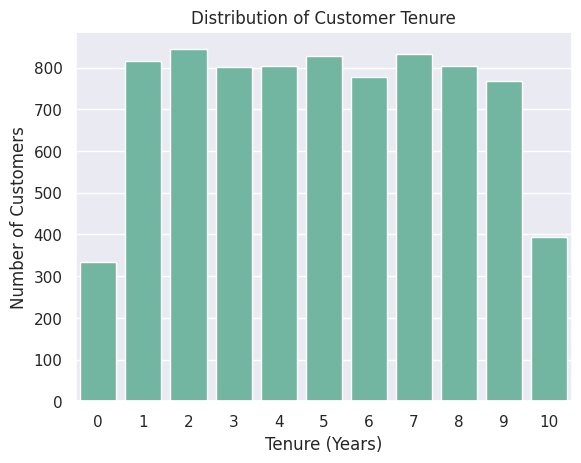

In [18]:
sns.countplot(data=train_data, x='tenure')
plt.title('Distribution of Customer Tenure')
plt.xlabel('Tenure (Years)')
plt.ylabel('Number of Customers')
plt.show()

Credit Score: Most customers have credit scores between 600 and 750, indicating generally moderate to good credit profiles.



Age: Most customers are aged 30–40, while older customers are less common.



Tenure: Customer tenure is relatively evenly distributed from 0 to 10 years, with no clear concentration in a specific group.



Balance: Many customers have a zero balance, while customers with positive balances typically hold around 100,000–150,000.



Products Number: Most customers use one or two products, suggesting opportunities to increase cross-selling.



Estimated Salary: Salaries are relatively evenly distributed across the range, with no obvious dominant income group.

*Bivariate dataset*

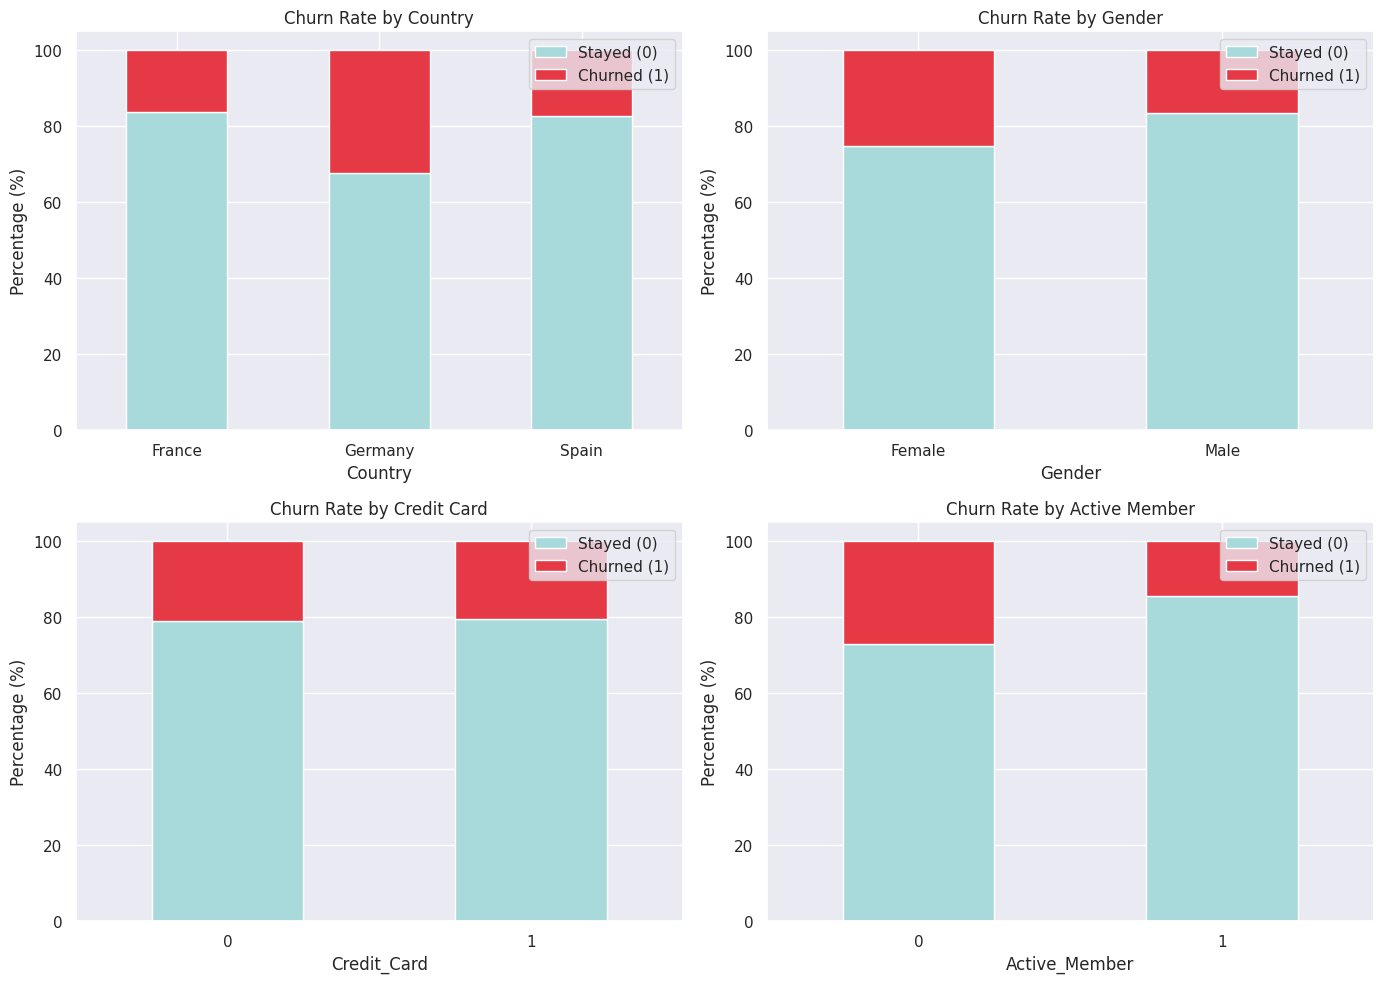

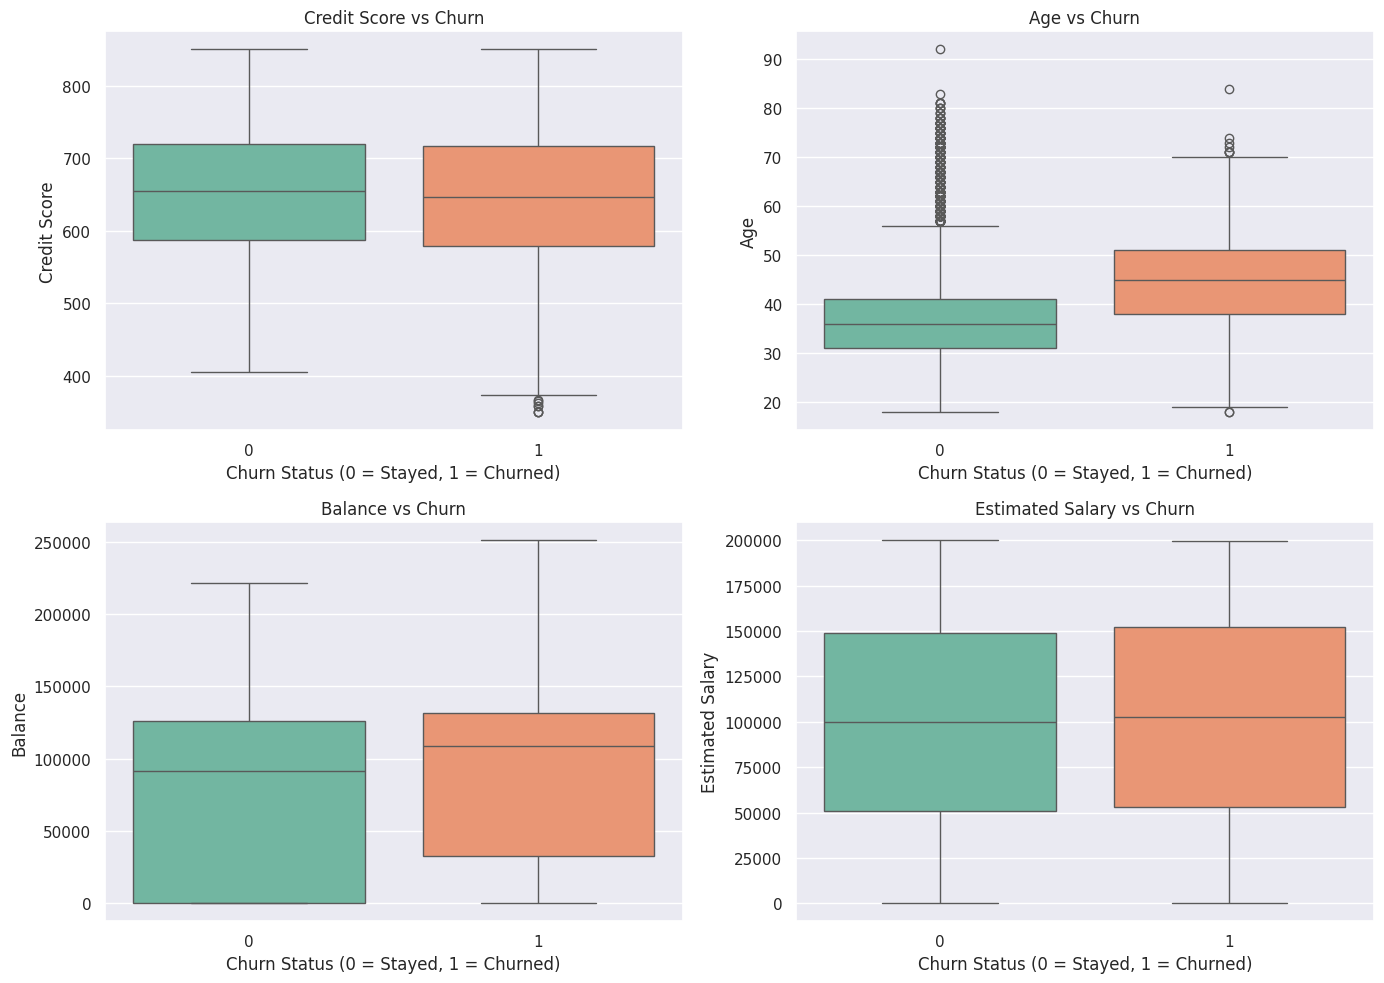

In [19]:
# 1. Compare Churn across Categorical & Binary features
cat_features = ['country', 'gender', 'credit_card', 'active_member']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    # Create a normalized percentage comparison
    df_perc = train_data.groupby(col)['churn'].value_counts(normalize=True).unstack() * 100
    df_perc.plot(kind='bar', stacked=True, ax=axes[i], color=['#a8dadc', '#e63946'])

    axes[i].set_title(f'Churn Rate by {col.replace("_", " ").title()}', fontsize=12)
    axes[i].set_ylabel('Percentage (%)')
    axes[i].set_xlabel(col.title())
    axes[i].legend(['Stayed (0)', 'Churned (1)'], loc='upper right')
    axes[i].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

# 2. Compare Churn across Numerical features (Fixed FutureWarnings)
num_features = ['credit_score', 'age', 'balance', 'estimated_salary']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(num_features):
    # Assigned x to hue and set legend=False to fix the FutureWarning
    sns.boxplot(data=train_data, x='churn', y=col, ax=axes[i], palette='Set2', hue='churn', legend=False)
    axes[i].set_title(f'{col.replace("_", " ").title()} vs Churn', fontsize=12)
    axes[i].set_xlabel('Churn Status (0 = Stayed, 1 = Churned)')
    axes[i].set_ylabel(col.replace("_", " ").title())

plt.tight_layout()
plt.show()

In [20]:
from scipy.stats import ttest_ind

# 1. Test hypothesis for AGE
age_churned = train_data[train_data['churn'] == 1]['age']
age_stayed = train_data[train_data['churn'] == 0]['age']

t_stat_age, p_val_age = ttest_ind(age_churned, age_stayed, equal_var=False)

print("=== AGE TEST ===")
print(f"T-statistic: {t_stat_age:.4f}")
print(f"P-value: {p_val_age:.4e}")
if p_val_age < 0.05:
    print("Reject H0: Age is significantly different between churned and stayed customers.")
else:
    print("Fail to reject H0: No significant difference in age.")

print("\n" + "="*20 + "\n")

# 2. Test hypothesis for BALANCE
balance_churned = train_data[train_data['churn'] == 1]['balance']
balance_stayed = train_data[train_data['churn'] == 0]['balance']

t_stat_bal, p_val_bal = ttest_ind(balance_churned, balance_stayed, equal_var=False)

print("=== BALANCE TEST ===")
print(f"T-statistic: {t_stat_bal:.4f}")
print(f"P-value: {p_val_bal:.4e}")
if p_val_bal < 0.05:
    print("Reject H0: Balance is significantly different between churned and stayed customers.")
else:
    print("Fail to reject H0: No significant difference in balance.")

=== AGE TEST ===
T-statistic: 26.9546
P-value: 1.6770e-141
Reject H0: Age is significantly different between churned and stayed customers.


=== BALANCE TEST ===
T-statistic: 11.1647
P-value: 2.4789e-28
Reject H0: Balance is significantly different between churned and stayed customers.


# Data preperation

*Handle outlier*

In [21]:
def remove_outliers(bank_data, numeric_columns, threshold=1.5):
    df_no_outliers = bank_data.copy()

    for column in numeric_columns:
        # Calculate IQR
        Q1 = df_no_outliers[column].quantile(0.25)
        Q3 = df_no_outliers[column].quantile(0.75)
        IQR = Q3 - Q1

        # Define bounds
        lower_bound = Q1 - threshold * IQR
        upper_bound = Q3 + threshold * IQR

        # Filter out outliers
        df_no_outliers = df_no_outliers[
            (df_no_outliers[column] >= lower_bound) & (df_no_outliers[column] <= upper_bound)
        ]

    return df_no_outliers

In [22]:
# Apply the function
train = remove_outliers(train_data, number_cols)

In [23]:
train.shape

(7658, 12)

In [24]:
train.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
9254,15601116,686,France,Male,32,6,0.00,2,1,1,179093.26,0
1561,15766374,632,Germany,Male,42,4,119624.60,2,1,1,195978.86,0
1670,15716994,559,Spain,Male,24,3,114739.92,1,1,0,85891.02,1
6087,15730759,561,France,Female,27,9,135637.00,1,1,0,153080.40,1
6669,15797900,517,France,Male,56,9,142147.32,1,0,0,39488.04,1


## Drop Unused Columns

In [25]:
train.drop(columns="customer_id", inplace=True)
test_data.drop(columns="customer_id", inplace=True)

In [26]:
train.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
9254,686,France,Male,32,6,0.00,2,1,1,179093.26,0
1561,632,Germany,Male,42,4,119624.60,2,1,1,195978.86,0
1670,559,Spain,Male,24,3,114739.92,1,1,0,85891.02,1
6087,561,France,Female,27,9,135637.00,1,1,0,153080.40,1
6669,517,France,Male,56,9,142147.32,1,0,0,39488.04,1


In [27]:
test_data.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
6252,596,Germany,Male,32,3,96709.07,2,0,0,41788.37,0
4684,623,France,Male,43,1,0.00,2,1,1,146379.30,0
1731,601,Spain,Female,44,4,0.00,2,1,0,58561.31,0
4742,506,Germany,Male,59,8,119152.10,2,1,1,170679.74,0
4521,560,Spain,Female,27,7,124995.98,1,1,1,114669.79,0


##Categorical Encoding

In [32]:
from sklearn.preprocessing import OneHotEncoder
one_hot_encoder = OneHotEncoder(drop='first', sparse_output=False)

In [33]:
# Categorical columns encoding
cat_features= ['country', 'gender']
# fit an encoder and transform the trainset
cat_vals = train[cat_features]
cat_vals

,country,gender
9254,France,Male
1561,Germany,Male
1670,Spain,Male
6087,France,Female
6669,France,Male
...,...,...
5734,France,Male
5191,France,Female
5390,France,Female
860,France,Male


In [35]:
# Fit and transform the categorical values DataFrame (cat_vals), not the list of column names
transformed = one_hot_encoder.fit_transform(cat_vals)
transformed

array([[0., 0., 1.],
       [1., 0., 1.],
       [0., 1., 1.],
       ...,
       [0., 0., 0.],
       [0., 0., 1.],
       [1., 0., 1.]])

In [37]:
# the names of the new columns
new_col_names = one_hot_encoder.get_feature_names_out(cat_features)
new_col_names

array(['country_Germany', 'country_Spain', 'gender_Male'], dtype=object)

In [38]:
# put the transformed data as columns in the trainset dataframe
for i, new_col_name in enumerate(new_col_names):
    train[new_col_name] = transformed[:,i]

# check if the dummies are produced correctly in the trainset
train.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn,country_Germany,country_Spain,gender_Male
9254,686,France,Male,32,6,0.00,2,1,1,179093.26,0,0.0,0.0,1.0
1561,632,Germany,Male,42,4,119624.60,2,1,1,195978.86,0,1.0,0.0,1.0
1670,559,Spain,Male,24,3,114739.92,1,1,0,85891.02,1,0.0,1.0,1.0
6087,561,France,Female,27,9,135637.00,1,1,0,153080.40,1,0.0,0.0,0.0
6669,517,France,Male,56,9,142147.32,1,0,0,39488.04,1,0.0,0.0,1.0


In [39]:
# delete the original categorical columns
train = train.drop(cat_features, axis=1)

In [40]:
train.head()

,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn,country_Germany,country_Spain,gender_Male
9254,686,32,6,0.00,2,1,1,179093.26,0,0.0,0.0,1.0
1561,632,42,4,119624.60,2,1,1,195978.86,0,1.0,0.0,1.0
1670,559,24,3,114739.92,1,1,0,85891.02,1,0.0,1.0,1.0
6087,561,27,9,135637.00,1,1,0,153080.40,1,0.0,0.0,0.0
6669,517,56,9,142147.32,1,0,0,39488.04,1,0.0,0.0,1.0


# Test set

In [43]:
# categorical columns to transform
cat_features = ["country", "gender"]

# fit an encoder and transform the testset
cat_vals = test_data[cat_features]
cat_vals

,country,gender
6252,Germany,Male
4684,France,Male
1731,Spain,Female
4742,Germany,Male
4521,Spain,Female
...,...,...
6412,Germany,Female
8285,France,Male
7853,France,Female
1095,France,Male


In [44]:
# Fit and transform the categorical values
transformed = one_hot_encoder.fit_transform(cat_vals)
transformed

array([[1., 0., 1.],
       [0., 0., 1.],
       [0., 1., 0.],
       ...,
       [0., 0., 0.],
       [0., 0., 1.],
       [1., 0., 1.]])

In [45]:
new_col_names = one_hot_encoder.get_feature_names_out(cat_features)
new_col_names

array(['country_Germany', 'country_Spain', 'gender_Male'], dtype=object)

In [46]:
# put the transformed data as columns in the testset dataframe
for i, new_col_name in enumerate(new_col_names):
    test_data[new_col_name] = transformed[:,i]

# check if the dummies are produced correctly in the testset
test_data.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn,country_Germany,country_Spain,gender_Male
6252,596,Germany,Male,32,3,96709.07,2,0,0,41788.37,0,1.0,0.0,1.0
4684,623,France,Male,43,1,0.00,2,1,1,146379.30,0,0.0,0.0,1.0
1731,601,Spain,Female,44,4,0.00,2,1,0,58561.31,0,0.0,1.0,0.0
4742,506,Germany,Male,59,8,119152.10,2,1,1,170679.74,0,1.0,0.0,1.0
4521,560,Spain,Female,27,7,124995.98,1,1,1,114669.79,0,0.0,1.0,0.0


In [48]:
# delete the original categorical columns
test = test_data.drop(cat_features, axis=1)

In [49]:
test.head()

,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn,country_Germany,country_Spain,gender_Male
6252,596,32,3,96709.07,2,0,0,41788.37,0,1.0,0.0,1.0
4684,623,43,1,0.00,2,1,1,146379.30,0,0.0,0.0,1.0
1731,601,44,4,0.00,2,1,0,58561.31,0,0.0,1.0,0.0
4742,506,59,8,119152.10,2,1,1,170679.74,0,1.0,0.0,1.0
4521,560,27,7,124995.98,1,1,1,114669.79,0,0.0,1.0,0.0
